<center><h1>Gu_Xinpeng_HW7</h1></center>

Name: Gu Xinpeng
<br>
Github Username: MarshG778
<br>
USC ID: 1678041153

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import balanced_accuracy_score, silhouette_score
from sklearn.cluster import KMeans
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform

DATA_DIR = "Anuran Calls (MFCCs)"

### (a) Download the Anuran Calls (MFCCs) Data Set

In [10]:
df = pd.read_csv(f'{DATA_DIR}/Frogs_MFCCs.csv')
labels = ['Family', 'Genus', 'Species']
X = df.iloc[:, :22]            # the 22 MFCCs; RecordID is not a feature
Y = df[labels]
print(df.shape, "| missing values:", df.isna().sum().sum())

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=0.7, random_state=0)
print(X_train.shape, X_test.shape)
for lab in labels:
    print(lab, Y_train[lab].value_counts().to_dict())
df.head()

(7195, 26) | missing values: 0
(5036, 22) (2159, 22)
Family {'Leptodactylidae': 3093, 'Hylidae': 1508, 'Dendrobatidae': 387, 'Bufonidae': 48}
Genus {'Adenomera': 2910, 'Hypsiboas': 1107, 'Ameerega': 387, 'Dendropsophus': 214, 'Leptodactylus': 183, 'Scinax': 101, 'Osteocephalus': 86, 'Rhinella': 48}
Species {'AdenomeraHylaedactylus': 2449, 'HypsiboasCordobae': 786, 'AdenomeraAndre': 461, 'Ameeregatrivittata': 387, 'HypsiboasCinerascens': 321, 'HylaMinuta': 214, 'LeptodactylusFuscus': 183, 'ScinaxRuber': 101, 'OsteocephalusOophagus': 86, 'Rhinellagranulosa': 48}


,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,...,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,...,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,...,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,...,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,...,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1


### (b) Train a classifier for each label

#### (i) Research

Evaluating a multi-label classifier

Every instance has a label triple of family, genus and species. Let Y be the true triple and Z the predicted triple.

Exact match ratio, also called subset accuracy. An instance counts as correct only if all three labels are predicted correctly, and the ratio is the share of such instances. It is the strictest measure, because one wrong label makes the whole instance wrong and a partly correct prediction gets no credit.

Hamming distance. For one instance this is the number of the three labels that are predicted wrongly, so it is 0, 1, 2 or 3. I report its average over the instances.

Hamming loss. This is the average share of wrongly predicted labels, which here is the Hamming distance divided by 3.

Hamming score. This is the average share of correctly predicted labels, so here it is 1 minus the Hamming loss. Sorower defines the Hamming score on sets of labels as the size of the intersection of the true and predicted label sets divided by the size of their union. Because each of our three labels comes from its own set of classes, I count the correct positions of the triple instead.

I also report the accuracy of each of the three classifiers and its balanced accuracy, which is the average recall over the classes. The balanced accuracy shows how well the rare classes are classified, which plain accuracy hides.

#### (ii) Train a SVM for each of the labels

In [12]:
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)
rows = []

def multilabel_scores(pred, true):
    wrong = (pred[labels].values != true[labels].values)
    dist = wrong.sum(axis=1)
    out = {'Exact match': (dist == 0).mean(),
           'Hamming distance': dist.mean(),
           'Hamming score': 1 - dist.mean() / 3,
           'Hamming loss': dist.mean() / 3}
    for i, lab in enumerate(labels):
        out[f'{lab} acc'] = 1 - wrong[:, i].mean()
        out[f'{lab} bal.acc'] = balanced_accuracy_score(true[lab], pred[lab])
    return out

def add_result(name, pred_train, pred_test):
    for split, p, t in [('train', pred_train, Y_train), ('test', pred_test, Y_test)]:
        rows.append({'Model': name, 'Split': split, **multilabel_scores(p, t)})

def fit_per_label(make_model, grid):
    searches, pred_tr, pred_te = {}, {}, {}
    for lab in labels:
        gs = GridSearchCV(make_model(), grid, cv=skf, n_jobs=-1).fit(X_train, Y_train[lab])
        searches[lab] = gs
        pred_tr[lab], pred_te[lab] = gs.predict(X_train), gs.predict(X_test)
        print(f"{lab}: best {gs.best_params_}, 10-fold CV accuracy = {gs.best_score_:.4f}, "
              f"test accuracy = {gs.score(X_test, Y_test[lab]):.4f}")
    return searches, pd.DataFrame(pred_tr), pd.DataFrame(pred_te)

def make_rbf(scale):
    base = OneVsRestClassifier(SVC(kernel='rbf'))
    return make_pipeline(StandardScaler(), base) if scale else base

C_GRID = [0.1, 1, 10, 100, 1000]
settings = [(False, 'RBF SVM, raw features', 'estimator__', [0.1, 0.3, 1, 3, 10]),
            (True, 'RBF SVM, standardized features', 'onevsrestclassifier__estimator__', [0.003, 0.01, 0.03, 0.1, 0.3])]
for scale, name, p, gammas in settings:
    print("=====", name)
    searches, ptr, pte = fit_per_label(lambda: make_rbf(scale), {p + 'C': C_GRID, p + 'gamma': gammas})
    add_result(name, ptr, pte)

===== RBF SVM, raw features
Family: best {'estimator__C': 100, 'estimator__gamma': 3}, 10-fold CV accuracy = 0.9934, test accuracy = 0.9958
Genus: best {'estimator__C': 10, 'estimator__gamma': 3}, 10-fold CV accuracy = 0.9903, test accuracy = 0.9935
Species: best {'estimator__C': 10, 'estimator__gamma': 3}, 10-fold CV accuracy = 0.9907, test accuracy = 0.9921
===== RBF SVM, standardized features
Family: best {'onevsrestclassifier__estimator__C': 100, 'onevsrestclassifier__estimator__gamma': 0.03}, 10-fold CV accuracy = 0.9919, test accuracy = 0.9935
Genus: best {'onevsrestclassifier__estimator__C': 10, 'onevsrestclassifier__estimator__gamma': 0.03}, 10-fold CV accuracy = 0.9901, test accuracy = 0.9917
Species: best {'onevsrestclassifier__estimator__C': 100, 'onevsrestclassifier__estimator__gamma': 0.03}, 10-fold CV accuracy = 0.9881, test accuracy = 0.9884


For each of the three labels I trained a one-versus-all SVM with a Gaussian kernel and chose the penalty C and the kernel parameter gamma by 10-fold stratified cross-validation. Gamma is related to the kernel width by sigma = 1 / sqrt(2 * gamma). I ran both the raw and the standardized attributes.

Raw attributes. The best values are C = 100 and gamma = 3 for family, and C = 10 and gamma = 3 for genus and species, so sigma is about 0.41. The 10-fold CV accuracies are 0.9934, 0.9903 and 0.9907, and the test accuracies are 0.9958, 0.9935 and 0.9921. The test exact match is 0.9907, the average Hamming distance is 0.0185, the Hamming score is 0.9938 and the Hamming loss is 0.0062.

Standardized attributes. The best gamma is 0.03 for all three labels, so sigma is about 4.1, with C = 100, 10 and 100. The CV accuracies are 0.9919, 0.9901 and 0.9881, and the test accuracies are 0.9935, 0.9917 and 0.9884. The test exact match is 0.9866, the Hamming distance is 0.0264, the Hamming score is 0.9912 and the Hamming loss is 0.0088.

None of the best values lies on the edge of its grid, so the grids are wide enough. The two versions give very similar results, and the raw attributes are a little better on every measure. This is plausible because the MFCCs are already normalized, and standardizing the columns changes the relative distances between the instances. The raw model has a training accuracy of 1.0 for all three labels, so it fits the training set perfectly, but the test accuracy is still above 0.99 and agrees closely with the CV accuracy. The test balanced accuracies are between 0.979 and 0.986, so the rare classes are also classified well. The accuracies are probably somewhat optimistic, because syllables of the same recording appear in both the training set and the test set.

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [13]:
C_GRID_L1 = [0.01, 0.1, 1, 10, 100]

def make_l1():
    return make_pipeline(StandardScaler(),
                         LinearSVC(penalty='l1', loss='squared_hinge', dual=False, max_iter=10000))

searches_l1, ptr, pte = fit_per_label(make_l1, {'linearsvc__C': C_GRID_L1})
add_result('L1 linear SVM', ptr, pte)
for lab in labels:
    coef = searches_l1[lab].best_estimator_[-1].coef_
    print(lab, "nonzero weights:", int((coef != 0).sum()), "of", coef.size)

Family: best {'linearsvc__C': 1}, 10-fold CV accuracy = 0.9377, test accuracy = 0.9338


/Users/marshg/anaconda3/envs/dsci552/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Genus: best {'linearsvc__C': 10}, 10-fold CV accuracy = 0.9519, test accuracy = 0.9477
Species: best {'linearsvc__C': 10}, 10-fold CV accuracy = 0.9607, test accuracy = 0.9569
Family nonzero weights: 84 of 88
Genus nonzero weights: 173 of 176
Species nonzero weights: 217 of 220


I repeated the experiment with a linear SVM with an L1 penalty on the standardized attributes and chose C by 10-fold cross-validation. The best C is 1 for family and 10 for genus and species. The CV accuracies are 0.9377, 0.9519 and 0.9607, and the test accuracies are 0.9338, 0.9477 and 0.9569. The test exact match is 0.9134, the average Hamming distance is 0.1616, the Hamming score is 0.9461 and the Hamming loss is 0.0539.

The linear model is clearly worse than the Gaussian kernel SVM. Its test Hamming loss is 0.0539 against 0.0062, and its exact match is 0.913 against 0.991. The classes are therefore not linearly separable, and the decision boundaries need the nonlinearity of the Gaussian kernel. The L1 penalty removes very few weights. The models keep 84 of 88 weights for family, 173 of 176 for genus and 217 of 220 for species, so nearly all of the 22 MFCCs are used, and L1 does not pick out a small subset of features.

The balanced accuracy is much lower than the accuracy for family, 0.698 against 0.934, and also for genus, 0.815 against 0.948, and for species, 0.892 against 0.957. The model does not classify the rare classes well, which motivates the next part.

#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [14]:
def make_l1_smote():
    return ImbPipeline([('scaler', StandardScaler()),
                        ('smote', SMOTE(random_state=0)),
                        ('svm', LinearSVC(penalty='l1', loss='squared_hinge', dual=False, max_iter=10000))])

searches_sm, ptr, pte = fit_per_label(make_l1_smote, {'svm__C': C_GRID_L1})
add_result('L1 linear SVM + SMOTE', ptr, pte)

results = pd.DataFrame(rows)
results.round(4)

/Users/marshg/anaconda3/envs/dsci552/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/marshg/anaconda3/envs/dsci552/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Family: best {'svm__C': 1}, 10-fold CV accuracy = 0.9242, test accuracy = 0.9125


/Users/marshg/anaconda3/envs/dsci552/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/marshg/anaconda3/envs/dsci552/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/marshg/anaconda3/envs/dsci552/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/marshg/anaconda3/envs/dsci552/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/marshg/anaconda3/envs/dsci552/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/marshg/anaconda3/e

Genus: best {'svm__C': 1}, 10-fold CV accuracy = 0.9237, test accuracy = 0.9032


/Users/marshg/anaconda3/envs/dsci552/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/marshg/anaconda3/envs/dsci552/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/marshg/anaconda3/envs/dsci552/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/marshg/anaconda3/envs/dsci552/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Species: best {'svm__C': 0.1}, 10-fold CV accuracy = 0.9563, test accuracy = 0.9532


,Model,Split,Exact match,Hamming distance,Hamming score,Hamming loss,Family acc,Family bal.acc,Genus acc,Genus bal.acc,Species acc,Species bal.acc
0,"RBF SVM, raw features",train,1.0000,0.0000,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,"RBF SVM, raw features",test,0.9907,0.0185,0.9938,0.0062,0.9958,0.9856,0.9935,0.9792,0.9921,0.9807
2,"RBF SVM, standardized features",train,0.9998,0.0002,0.9999,0.0001,1.0000,1.0000,0.9998,0.9994,1.0000,1.0000
3,"RBF SVM, standardized features",test,0.9866,0.0264,0.9912,0.0088,0.9935,0.9823,0.9917,0.9741,0.9884,0.9735
4,L1 linear SVM,train,0.9222,0.1408,0.9531,0.0469,0.9384,0.6946,0.9567,0.8314,0.9641,0.9068
5,L1 linear SVM,test,0.9134,0.1616,0.9461,0.0539,0.9338,0.6979,0.9477,0.8154,0.9569,0.8923
6,L1 linear SVM + SMOTE,train,0.8743,0.1833,0.9389,0.0611,0.9249,0.9450,0.9271,0.9387,0.9647,0.9379
7,L1 linear SVM + SMOTE,test,0.8555,0.2311,0.9230,0.0770,0.9125,0.9177,0.9032,0.9125,0.9532,0.9207


To address the class imbalance I applied SMOTE to the L1-penalized linear SVM. SMOTE is placed inside the cross-validation pipeline, so the synthetic cases are created from the training folds only, and the validation folds and the test set are not resampled. The best C is 1 for family and genus and 0.1 for species. The CV accuracies are 0.9242, 0.9237 and 0.9563, and the test accuracies are 0.9125, 0.9032 and 0.9532. In some fits liblinear stopped at the iteration limit with a convergence warning.

SMOTE raises the balanced accuracy a lot. For family it goes from 0.698 to 0.918, for genus from 0.815 to 0.913 and for species from 0.892 to 0.921, so the classifiers find many more of the rare classes. The price is a lower plain accuracy, from 0.934 to 0.913 for family, from 0.948 to 0.903 for genus and from 0.957 to 0.953 for species, because more cases of the large classes are now labelled as rare classes. The multi-label scores also fall. The test exact match goes from 0.913 to 0.856, the Hamming score from 0.946 to 0.923 and the Hamming loss from 0.054 to 0.077.

Conclusions about the classifiers. The Gaussian kernel SVM on the raw attributes is the best classifier on every measure, with a test exact match of 0.991, a Hamming loss of 0.006 and balanced accuracies of about 0.98, and it needs no correction for the imbalance. The linear L1 SVMs are clearly worse, because the classes are not linearly separable, and they keep almost all the features. SMOTE does what it is meant to do for the linear model, since the rare classes are classified much better, but the average accuracy and the exact match fall. Which version to prefer depends on whether the rare species or the overall accuracy matters more. The accuracies of all models are probably a little too high, because syllables of the same frog are in both the training and the test set.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

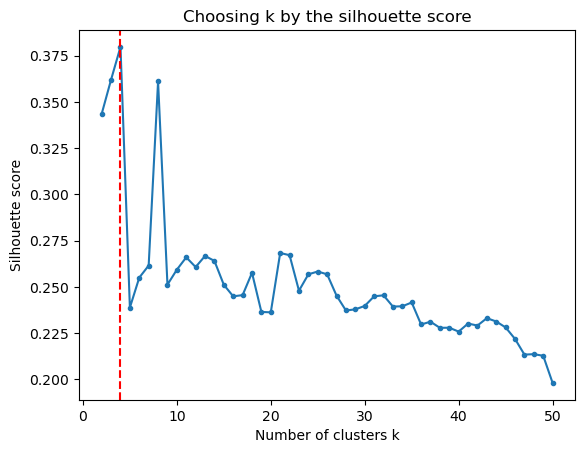

chosen k: 4 | silhouette: 0.3798


In [17]:
def cluster_scores(pred, true):
    dist = (pred[labels].values != true[labels].values).sum(axis=1)
    return {'Hamming distance': dist.mean(), 'Hamming score': 1 - dist.mean() / 3,
            'Hamming loss': dist.mean() / 3}

def one_run(seed, kmax=50):
    sil = {}
    for k in range(2, kmax + 1):
        km = KMeans(n_clusters=k, n_init=1, random_state=seed).fit(X)
        sil[k] = silhouette_score(X, km.labels_, sample_size=2000, random_state=seed)
    k_best = max(sil, key=sil.get)
    km = KMeans(n_clusters=k_best, n_init=10, random_state=seed).fit(X)
    cl = pd.Series(km.labels_, index=Y.index)
    maj = {lab: Y[lab].groupby(cl).agg(lambda s: s.value_counts().idxmax()) for lab in labels}
    pred = pd.DataFrame({lab: cl.map(maj[lab]) for lab in labels})
    return k_best, sil, maj, cl, cluster_scores(pred, Y)

k_best, sil, maj, cl, sc = one_run(0)
plt.plot(list(sil.keys()), list(sil.values()), marker='o', ms=3)
plt.axvline(k_best, color='r', ls='--')
plt.xlabel('Number of clusters k'); plt.ylabel('Silhouette score')
plt.title('Choosing k by the silhouette score'); plt.show()
print("chosen k:", k_best, "| silhouette:", round(sil[k_best], 4))

I ran k-means on the whole data set without splitting it and chose k between 2 and 50 with the silhouette score. The silhouette is not defined for k = 1, so the search starts at 2, and for speed it is computed on a random sample of 2000 instances. For the first run the silhouette is highest at k = 4, with a value of 0.380. A second, lower peak appears at k = 8, and for larger k the score falls from about 0.26 to 0.20, so more clusters do not give better separated clusters. In the 50 runs of part (c) the chosen k has a mean of 3.70 and a standard deviation of 1.05, so k = 4 is the typical choice, and sometimes a different value is picked.

### (b) Determine which family is the majority

In [19]:
table = pd.DataFrame({'size': cl.value_counts().sort_index()})
for lab in labels:
    table[lab] = maj[lab]
table

,size,Family,Genus,Species
0,3568,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,1982,Hylidae,Hypsiboas,HypsiboasCordobae
2,1031,Dendrobatidae,Ameerega,Ameeregatrivittata
3,614,Hylidae,Hypsiboas,HypsiboasCinerascens


For the run with k = 4 the majority labels of the clusters are:
Cluster 0, 3568 instances: Leptodactylidae, Adenomera, AdenomeraHylaedactylus.
Cluster 1, 1982 instances: Hylidae, Hypsiboas, HypsiboasCordobae.
Cluster 2, 1031 instances: Dendrobatidae, Ameerega, Ameeregatrivittata.
Cluster 3, 614 instances: Hylidae, Hypsiboas, HypsiboasCinerascens.

Clusters 1 and 3 have the same family and genus and differ only in species. The majority labels cover 3 of the 4 families, 3 of the 8 genera and 4 of the 10 species. The classes that never become a majority, for example the family Bufonidae and species such as AdenomeraAndre, can never be labelled correctly, so every instance of those classes has at least one wrong label.

### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [21]:
runs = []
for seed in range(50):
    k_b, _, _, _, sc = one_run(seed)
    runs.append({'seed': seed, 'k': k_b, **sc})
runs_df = pd.DataFrame(runs)
runs_df[['k', 'Hamming distance', 'Hamming score', 'Hamming loss']].agg(['mean', 'std'])

,k,Hamming distance,Hamming score,Hamming loss
mean,3.70000,0.742354,0.752549,0.247451
std,1.05463,0.135737,0.045246,0.045246


For each cluster the majority labels give a predicted triple for every instance, and I compared it with the true triple. Over the 50 Monte Carlo runs the average Hamming distance is 0.742 with a standard deviation of 0.136. The Hamming score is 0.753 with a standard deviation of 0.045, and the Hamming loss is 0.247 with a standard deviation of 0.045. So on average 0.74 of the 3 labels of an instance are wrong, which is about 25% of the labels. The score and the loss have the same standard deviation because they are linear functions of the distance, with loss = distance / 3 and score = 1 - loss.

These errors are far larger than those of the supervised SVMs, whose test Hamming loss lies between 0.006 and 0.077. This is expected, because k-means does not use the labels, and the silhouette criterion picks only about 4 clusters while there are 10 species, so many species cannot be recovered. The standard deviation comes from the random starts of k-means and from the changing number of clusters chosen in each run.

## 3. ISLR 12.6.2

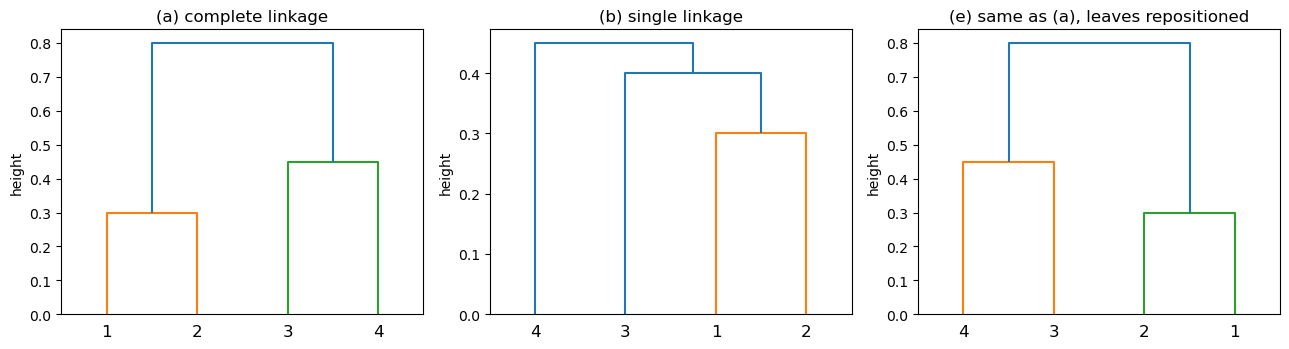

cut (a): [1 1 2 2] | cut (b): [1 1 1 2]


In [26]:
d = np.array([[0, .3, .4, .7], [.3, 0, .5, .8], [.4, .5, 0, .45], [.7, .8, .45, 0]])
cond = squareform(d)
Zc, Zs = linkage(cond, 'complete'), linkage(cond, 'single')
Ze = Zc.copy(); Ze[:, [0, 1]] = Ze[:, [1, 0]]    # swap the two branches at every fusion
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, Z, t in zip(axes, [Zc, Zs, Ze], ['(a) complete linkage', '(b) single linkage', '(e) same as (a), leaves repositioned']):
    dendrogram(Z, labels=['1', '2', '3', '4'], ax=ax); ax.set_title(t); ax.set_ylabel('height')
plt.tight_layout(); plt.show()
print("cut (a):", fcluster(Zc, 2, 'maxclust'), "| cut (b):", fcluster(Zs, 2, 'maxclust'))

The dissimilarities are d12 = 0.3, d13 = 0.4, d14 = 0.7, d23 = 0.5, d24 = 0.8 and d34 = 0.45. The dendrograms are in the plot above.

(a) Complete linkage. The smallest dissimilarity is 0.3, so observations 1 and 2 are fused first, at height 0.3. The complete-linkage distances are then 0.5 between {1,2} and 3, 0.8 between {1,2} and 4, and 0.45 between 3 and 4. The smallest is 0.45, so 3 and 4 are fused at height 0.45. Finally {1,2} and {3,4} are fused at height max(0.4, 0.7, 0.5, 0.8) = 0.8.

(b) Single linkage. Observations 1 and 2 are fused first, at height 0.3. The single-linkage distances are then 0.4 between {1,2} and 3, 0.7 between {1,2} and 4, and 0.45 between 3 and 4. The smallest is 0.4, so 3 joins {1,2} at height 0.4. Finally 4 joins {1,2,3} at height min(0.7, 0.8, 0.45) = 0.45.

(c) Cutting the dendrogram in (a) into two clusters gives {1, 2} and {3, 4}.

(d) Cutting the dendrogram in (b) into two clusters gives {1, 2, 3} and {4}.

(e) At every fusion the two branches can be swapped without changing the meaning. For example, swapping the branches at all three fusions gives the leaf order 4, 3, 2, 1, with the same heights 0.3, 0.45 and 0.8. Swapping only observations 1 and 2, which gives the order 2, 1, 3, 4, is also an equivalent dendrogram.